# 3-Qubit Phase-Flip Code

A phase flip (Z error) looks like a bit flip in the |+⟩/|−⟩ basis, so this is the
bit-flip code with Hadamards: α|0⟩ + β|1⟩ is encoded as α|+++⟩ + β|−−−⟩.
The syndrome is measured with H–CNOT–H (X-parity checks), and a **Z** gate on
the identified qubit corrects the error.

| Syndrome (c1 c0) | 00 | 01 | 11 | 10 |
|---|---|---|---|---|
| Phase-flipped qubit | none | q[0] | q[1] | q[2] |

**Inputs:** amplitudes a and b and the error qubit (0, 1 or 2).
The second cell saves the circuit diagram as a PNG.

Enter amplitude a:  0.8
Enter amplitude b:  0.6



Original input:
(0.8+0j)|0> + (0.6+0j)|1>



Enter error qubit (0, 1, or 2):  2



Syndrome (c1 c0): 10

Error detection result:
Phase-flip error detected at q[2].
Z gate applied to q[2] for correction.

Original state:
0.800000|0> + 0.600000|1>

Recovered state after phase-flip correction:
0.800000|0> + 0.600000|1>

Quantum Circuit:


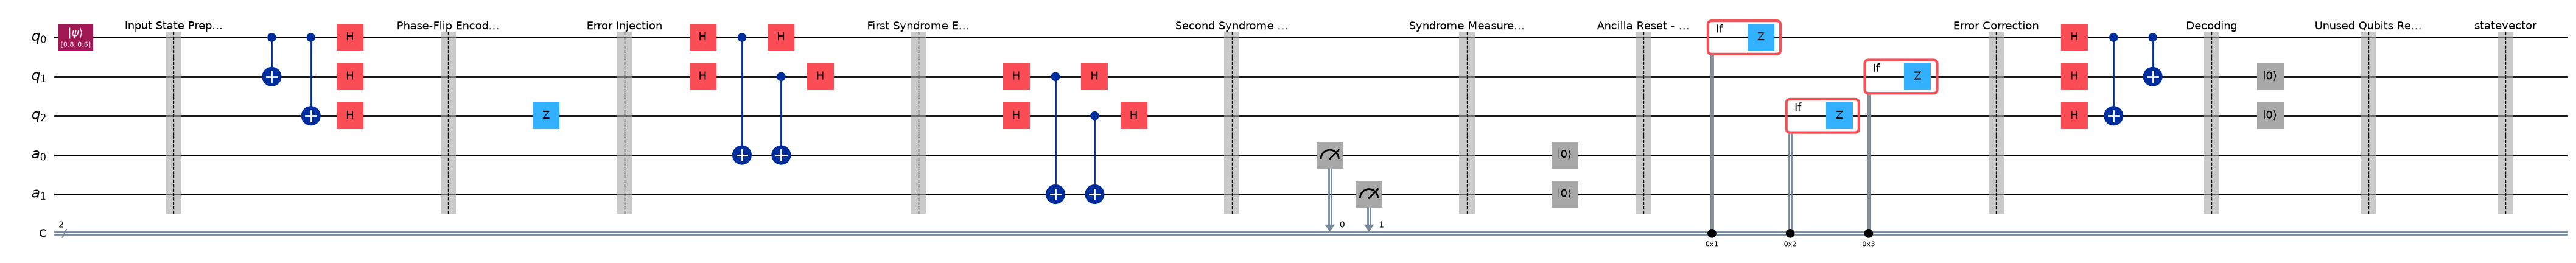

In [6]:

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit_aer import AerSimulator
import numpy as np

# Registers
q = QuantumRegister(3, 'q')
a = QuantumRegister(2, 'a')
c = ClassicalRegister(2, 'c')

qc = QuantumCircuit(q, a, c)

# ------------------------------------------------
# INPUT STATE PREPARATION
# ------------------------------------------------

alpha = complex(input("Enter amplitude a: "))
beta = complex(input("Enter amplitude b: "))

# Normalize input state
norm = np.sqrt(abs(alpha)**2 + abs(beta)**2)

if norm == 0:
    raise ValueError("Input state cannot be zero.")

alpha = alpha / norm
beta = beta / norm

qc.initialize([alpha, beta], q[0])
qc.barrier(label="Input State Preparation")

print("\nOriginal input:")
print(f"{alpha}|0> + {beta}|1>")


# ------------------------------------------------
# ENCODING (PHASE-FLIP CODE)
# ------------------------------------------------

qc.cx(q[0], q[1])
qc.cx(q[0], q[2])

# Convert to Hadamard basis
qc.h(q)
qc.barrier(label="Phase-Flip Encoding")


# ------------------------------------------------
# INTRODUCE PHASE-FLIP ERROR
# ------------------------------------------------

error_bit = int(input("\nEnter error qubit (0, 1, or 2): "))

if error_bit not in [0, 1, 2]:
    raise ValueError("Enter only 0, 1, or 2.")

qc.z(q[error_bit])
qc.barrier(label="Error Injection")


# ------------------------------------------------
# SYNDROME EXTRACTION - FIRST STABILIZER
# ------------------------------------------------

# First stabilizer: X0 X1
qc.h(q[0])
qc.h(q[1])

qc.cx(q[0], a[0])
qc.cx(q[1], a[0])

qc.h(q[0])
qc.h(q[1])

qc.barrier(label="First Syndrome Extraction")


# ------------------------------------------------
# SYNDROME EXTRACTION - SECOND STABILIZER
# ------------------------------------------------

# Second stabilizer: X1 X2
qc.h(q[1])
qc.h(q[2])

qc.cx(q[1], a[1])
qc.cx(q[2], a[1])

qc.h(q[1])
qc.h(q[2])

qc.barrier(label="Second Syndrome Extraction")


# ------------------------------------------------
# SYNDROME MEASUREMENT
# ------------------------------------------------

qc.measure(a[0], c[0])
qc.measure(a[1], c[1])
qc.barrier(label="Syndrome Measurement")


# ------------------------------------------------
# ANCILLA RESET
# ------------------------------------------------

qc.reset(a[0])
qc.reset(a[1])

qc.barrier(label="Ancilla Reset - Available for Reuse")


# ------------------------------------------------
# ERROR CORRECTION USING Z GATES
# ------------------------------------------------

with qc.if_test((c, 1)):
    qc.z(q[0])

with qc.if_test((c, 2)):
    qc.z(q[2])

with qc.if_test((c, 3)):
    qc.z(q[1])

qc.barrier(label="Error Correction")


# ------------------------------------------------
# DECODING
# ------------------------------------------------

# Convert back to computational basis
qc.h(q)

# Decode the encoded state
qc.cx(q[0], q[2])
qc.cx(q[0], q[1])

qc.barrier(label="Decoding")


# ------------------------------------------------
# RESET UNUSED DATA QUBITS
# ------------------------------------------------

qc.reset(q[1])
qc.reset(q[2])

qc.barrier(label="Unused Qubits Reset - Available for Reuse")


# ------------------------------------------------
# SAVE FINAL STATEVECTOR
# ------------------------------------------------

qc.save_statevector()


# ------------------------------------------------
# RUN SIMULATION
# ------------------------------------------------

backend = AerSimulator(method="statevector")

result = backend.run(qc, shots=1).result()

final_state = result.get_statevector(qc)


# ------------------------------------------------
# EXTRACT SYNDROME
# ------------------------------------------------

counts = result.get_counts(qc)

syndrome = int(
    max(counts, key=counts.get).replace(" ", ""), 2
)

print("\nSyndrome (c1 c0):", format(syndrome, "02b"))


# ------------------------------------------------
# IDENTIFY ERROR LOCATION
# ------------------------------------------------

print("\nError detection result:")

if syndrome == 0:
    print("No phase-flip error detected.")

elif syndrome == 1:
    print("Phase-flip error detected at q[0].")
    print("Z gate applied to q[0] for correction.")

elif syndrome == 2:
    print("Phase-flip error detected at q[2].")
    print("Z gate applied to q[2] for correction.")

elif syndrome == 3:
    print("Phase-flip error detected at q[1].")
    print("Z gate applied to q[1] for correction.")


# ------------------------------------------------
# EXTRACT RECOVERED AMPLITUDES
# ------------------------------------------------

# All qubits except q[0] are now reset to |0>
# Qiskit uses little-endian statevector ordering

alpha_out = final_state.data[0]
beta_out = final_state.data[1]

# Normalize recovered state
norm_out = np.sqrt(
    abs(alpha_out)**2 + abs(beta_out)**2
)

if norm_out == 0:
    raise ValueError("Recovered state has zero probability amplitude.")

alpha_out = alpha_out / norm_out
beta_out = beta_out / norm_out


# ------------------------------------------------
# FORMAT COMPLEX AMPLITUDES
# ------------------------------------------------

def format_amplitude(value):
    real = value.real
    imag = value.imag

    if abs(imag) < 1e-8:
        return f"{real:.6f}"

    if abs(real) < 1e-8:
        return f"{imag:.6f}j"

    sign = "+" if imag >= 0 else "-"
    return f"{real:.6f} {sign} {abs(imag):.6f}j"


# ------------------------------------------------
# DISPLAY RECOVERED STATE
# ------------------------------------------------

print("\nOriginal state:")
print(f"{format_amplitude(alpha)}|0> + "
      f"{format_amplitude(beta)}|1>")

print("\nRecovered state after phase-flip correction:")
print(f"{format_amplitude(alpha_out)}|0> + "
      f"{format_amplitude(beta_out)}|1>")


# ------------------------------------------------
# DISPLAY CIRCUIT
# ------------------------------------------------

print("\nQuantum Circuit:")

qc.draw(output='mpl', fold=-1, scale=1.0)


In [7]:
fig = qc.draw(output="mpl", fold=-1, scale=1.0)
fig.savefig("3_2_PhaseFlip.png", dpi=300, bbox_inches="tight")